# Dinâmica da Criminalidade no Rio de Janeiro: Uma Análise Integrada Sobre Segurança Pública

*Análise Exploratória de Dados e Visualização*  
*FGV EMAp - Escola de Matemática Aplicada | Semestre 2026.2*

*Professor:* João Rulff  
 
*Autores:*   
Josué Santos de Oliveira da Silva   
Leonardo Cardia Bicca   
Luigi Parmeggiani Porto

Repositório do projeto: https://github.com/Josue-santoss/AEDV-A2-.git

## Introdução:

&emsp;O estado do Rio de Janeiro vivencia, há décadas, um dos cenários de segurança pública mais desafiadores e militarizados da América Latina. O presente artigo investiga a arquitetura espaço-temporal da violência letal fluminense a partir do cruzamento de 14 bases de microdados abertos fornecidas pelo Instituto de Segurança Pública (ISP-RJ), cobrindo o período longitudinal de 2003 a 2024. Estruturado em torno de sete perguntas de domínio articuladas lógica e metodologicamente, o estudo aborda desde a substituição tecnológica nos arsenais do crime organizado até as dinâmicas territoriais de letalidade policial e violência de gênero.  

## O Que o Leitor deve Saber:

1. Sobre os dados: Os dados têm origem no Instituto de Segurança Pública do Estado do Rio de Janeiro (ISP-RJ) e estão
estruturados em um conjunto de bases de dados abertas de frequências mensal e anual. A coleta e agregação
originais são feitas através dos registros de ocorrência das delegacias do estado.
Utilizaremos diversas tabelas relacionais que cobrem diferentes dimensões da segurança. As variáveis
mais relevantes para a análise incluem os recortes temporais e geográficos, tipificações de armas apreendidas
(com destaque para fuzis) e contagens e taxas (por 100 mil habitantes) de crimes contra a vida. Utilizaremos
também a tabela de relação CISP-AISP-RISP para realizar cruzamentos de dados espaciais entre os níveis
de delegacia, município e estado.


2. Siglas:  
- CISP: A Circunscrição Integrada de Segurança Pública é a área territorial que coincide com a jurisdição de uma delegacia distrital da Polícia Civil (SEPOL) e a subárea correspondente de uma companhia da Polícia Militar (SEPM).  
- AISP: A Área Integrada de Segurança Pública é uma divisão territorial que alinha a atuação da Polícia Militar (PMERJ) e da Polícia Civil (PCERJ) na mesma região para combater a criminalidade de forma conjunta.  
- RISP: A Região Integrada de Segurança Pública une os comandos intermediários das polícias, ou seja, os Departamentos de Polícia de Área (DPA) da Polícia Civil e os Comandos de Policiamento de Área (CPA) da Polícia Militar.

# Importação das Bibliotecas Utilizadas:

In [247]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.io as pio
import plotly.express as px
import tempfile
import os
import sys    
import requests
from matplotlib.patches import Patch


# Carregamento de Dados:

In [248]:
from io import BytesIO
from zipfile import ZipFile



url = "https://github.com/josue-fgv/AEDV-A2-/archive/refs/heads/main.zip"

resposta = requests.get(url, timeout=60)
resposta.raise_for_status()

prefixo = "br_rj_isp_estatisticas_seguranca_"
dataframes = {}

with ZipFile(BytesIO(resposta.content)) as zip_ref:
    for caminho in zip_ref.namelist():

        if "/Projeto/Datas/" in caminho and caminho.endswith(".csv"):

            arquivo = caminho.split("/")[-1]
            nome = arquivo.removesuffix(".csv").removeprefix(prefixo)

            with zip_ref.open(caminho) as conteudo:
                dataframes[nome] = pd.read_csv(
                    conteudo,
                    sep=None,
                    engine="python"
                )

            print(f"{nome}: importado com sucesso!")


PopulacaoEvolucaoMensalCisp: importado com sucesso!
armas_apreendidas_mensal: importado com sucesso!
armas_fogo_apreendidas_mensal: importado com sucesso!
evolucao_mensal_cisp: importado com sucesso!
evolucao_mensal_municipio: importado com sucesso!
evolucao_mensal_uf: importado com sucesso!
evolucao_mensal_upp: importado com sucesso!
evolucao_policial_morto_servico_mensal: importado com sucesso!
feminicidio_mensal_cisp: importado com sucesso!
relacao_cisp_aisp_risp: importado com sucesso!
taxa_evolucao_anual_municipio: importado com sucesso!
taxa_evolucao_anual_uf: importado com sucesso!
taxa_evolucao_mensal_municipio: importado com sucesso!
taxa_evolucao_mensal_uf: importado com sucesso!
taxa_letalidade: importado com sucesso!


In [249]:
(
    df_armas,
    df_armas_fogo,
    df_cisp_mensal,
    df_mun_mensal,
    df_evol_uf,
    df_evol_upp,
    df_policial,
    df_fem_cisp,
    df_rel,
    df_taxa_anual_municipio,
    df_taxa_anual_uf,
    df_taxa_mun_mensal,
    df_taxa_mensal_uf,
    df_letalidade,
    df_populacao_mensal_cisp
) = (
    dataframes["armas_apreendidas_mensal"],
    dataframes["armas_fogo_apreendidas_mensal"],
    dataframes["evolucao_mensal_cisp"],
    dataframes["evolucao_mensal_municipio"],
    dataframes["evolucao_mensal_uf"],
    dataframes["evolucao_mensal_upp"],
    dataframes["evolucao_policial_morto_servico_mensal"],
    dataframes["feminicidio_mensal_cisp"],
    dataframes["relacao_cisp_aisp_risp"],
    dataframes["taxa_evolucao_anual_municipio"],
    dataframes["taxa_evolucao_anual_uf"],
    dataframes["taxa_evolucao_mensal_municipio"],
    dataframes["taxa_evolucao_mensal_uf"],
    dataframes["taxa_letalidade"],
    dataframes["PopulacaoEvolucaoMensalCisp"]
)


# Limpeza de dados

In [250]:
def limpar_bases_isp(dataframes: dict) -> dict:
    """
    Aplica uma rotina padronizada de limpeza, tipagem e adequação temporal 
    a todas as bases de segurança do ISP-RJ contidas no dicionário.
    """
    correcoes_texto = {
        "Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i": "Grande Niterói",
        "Grande Niteroi": "Grande Niterói"
    }
    
    for nome, df in dataframes.items():
        
        # Imputação de Nulos em Variáveis Contínuas/Discretas
        # Na série do ISP, a ausência de dados em delitos granulares implica em 0 ocorrências.
        colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns
        df[colunas_numericas] = df[colunas_numericas].fillna(0)
        
        colunas_texto = df.select_dtypes(include=['object', 'string']).columns
        for col in colunas_texto:
            # Remoção de espaços em branco nas extremidades
            df[col] = df[col].astype(str).str.strip()
            
            if col == 'regiao':
                df[col] = df[col].replace(correcoes_texto)
                
        
        if 'ano' in df.columns and 'mes' in df.columns:
            # Adequação forçada para int, prevenindo conversão de floats (ex: 2018.0)
            df['ano'] = df['ano'].astype(int)
            df['mes'] = df['mes'].astype(int)
            
            # Geração da dimensão de tempo padronizada (YYYY-MM-01)
            df['data'] = pd.to_datetime(
                df['ano'].astype(str) + '-' + df['mes'].astype(str).str.zfill(2) + '-01', 
                errors='coerce'
            )
            


    return dataframes

dataframes = limpar_bases_isp(dataframes)

# Relacionamentos entre bancos de dados 

## Relacionamento entre AISP e Regiões

In [251]:
grupos = df_rel.groupby("regiao")["id_aisp"].unique()

(
    baixadas,
    centro_sul_fluminense,
    costa_verde,
    metropolitana,
    medio_paraiba,
    noroeste_fluminense,
    norte_fluminense,
    serrana
) = grupos.tolist()

print(grupos)

regiao
Baixadas Litorâneas                                           [25, 35, 32]
Centro-Sul Fluminense                                             [10, 38]
Costa Verde                                                           [33]
Metropolitana            [16, 17, 19, 2, 22, 23, 3, 4, 5, 6, 14, 18, 27...
Médio Paraíba                                                 [10, 28, 37]
Noroeste Fluminense                                               [29, 36]
Norte Fluminense                                               [29, 32, 8]
Serrana                                                       [36, 11, 30]
Name: id_aisp, dtype: object


## População por Cisp 

In [252]:
df_populacao_mensal_cisp = df_populacao_mensal_cisp.rename(
    columns={"circ": "id_cisp", "pop_circ": "populacao"}
)
print(df_populacao_mensal_cisp.dtypes)

id_cisp               int64
mes                   int64
ano                   int64
populacao               str
data         datetime64[us]
dtype: object


In [253]:
df_populacao_mensal_cisp["populacao"] = (
    df_populacao_mensal_cisp["populacao"]
    .str.replace(",", ".", regex=False)
    .astype(float)
    .astype("int64")
)

In [254]:
#Soma mensal da população por ano e CISP.
df_populacao_anual_cisp = df_populacao_mensal_cisp.groupby(["ano", "id_cisp"])["populacao"].mean().reset_index()
df_populacao_anual_cisp




,ano,id_cisp,populacao
0,2003,1,1550.500000
1,2003,4,29894.000000
2,2003,5,35780.916667
3,2003,6,76537.083333
4,2003,7,38793.583333
...,...,...,...
2685,2022,159,59338.857143
2686,2022,165,44118.142857
2687,2022,166,202435.428571
2688,2022,167,43118.571429


## Nomeando os Aisps pela fonte"https://www.ispdados.rj.gov.br/Arquivos/Relacao_RISPxAISPxCISP.pdf"

In [255]:

nomes_aisp = {
    1: "São Gonçalo",
    2: "Botafogo / Flamengo",
    3: "Méier / Cachambi",
    4: "São Cristóvão / Estácio",
    5: "Centro / Santa Teresa",
    6: "Tijuca / Maracanã",
    7: "São Gonçalo",
    8: "Campos dos Goytacazes",
    9: "Madureira / Cascadura",
    10: "Barra do Piraí / Valença",
    11: "Nova Friburgo",
    12: "Niterói / Maricá",
    14: "Bangu / Realengo",
    15: "Duque de Caxias",
    16: "Penha / Olaria",
    17: "Ilha do Governador",
    18: "Jacarepaguá",
    19: "Copacabana / Leme",
    20: "Nova Iguaçu / Mesquita",
    21: "São João de Meriti",
    22: "Maré / Bonsucesso",
    23: "Ipanema / Leblon / Rocinha",
    24: "Itaguaí / Seropédica",
    25: "Região dos Lagos",
    26: "Petrópolis",
    27: "Santa Cruz / Guaratiba",
    28: "Volta Redonda / Barra Mansa",
    29: "Itaperuna",
    30: "Teresópolis",
    31: "Barra da Tijuca / Recreio",
    32: "Macaé / Rio das Ostras",
    33: "Angra dos Reis / Mangaratiba",
    34: "Magé / Guapimirim",
    35: "Itaboraí / Rio Bonito",
    36: "Santo Antônio de Pádua",
    37: "Resende / Itatiaia",
    38: "Três Rios / Paraíba do Sul",
    39: "Belford Roxo",
    40: "Campo Grande",
    41: "Irajá / Pavuna",
    43: "Paraty",
}

#criando uma coluna nova com o nome das aisp em df_populacao_por_ano_aisp
populacao_por_ano_aisp["nome_aisp"] = populacao_por_ano_aisp["id_aisp"].map(nomes_aisp)
populacao_por_ano_aisp

,ano,id_aisp,populacao,nome_aisp
0,2003,2.0,227239.333333,Botafogo / Flamengo
1,2003,3.0,525360.583333,Méier / Cachambi
2,2003,4.0,152657.083333,São Cristóvão / Estácio
3,2003,5.0,106019.000000,Centro / Santa Teresa
4,2003,6.0,351785.000000,Tijuca / Maracanã
...,...,...,...,...
775,2022,37.0,197879.428571,Resende / Itatiaia
776,2022,38.0,167015.714286,Três Rios / Paraíba do Sul
777,2022,39.0,515696.000000,Belford Roxo
778,2022,40.0,581682.714286,Campo Grande


## Relacionando CISP e AISP

In [256]:
aisp_de_cisp = (
    df_rel.groupby("id_cisp")["id_aisp"]
    .first()
    .to_dict()
)

populacao_por_ano_aisp = df_populacao_anual_cisp.copy()

populacao_por_ano_aisp["id_aisp"] = (
    populacao_por_ano_aisp["id_cisp"].map(aisp_de_cisp)
)

populacao_por_ano_aisp = (
    populacao_por_ano_aisp
    .groupby(["ano", "id_aisp"], as_index=False)["populacao"]
    .sum()
)

populacao_por_ano_aisp




,ano,id_aisp,populacao
0,2003,2.0,227239.333333
1,2003,3.0,525360.583333
2,2003,4.0,152657.083333
3,2003,5.0,106019.000000
4,2003,6.0,351785.000000
...,...,...,...
775,2022,37.0,197879.428571
776,2022,38.0,167015.714286
777,2022,39.0,515696.000000
778,2022,40.0,581682.714286


# Análise Estatística das aisps

In [257]:
#Mortes de aisp por ano.

mortes_aisp_ano = (
    df_cisp_mensal
    .groupby(["ano", "id_aisp"], as_index=False)
    ["quantidade_letalidade_violenta"]
    .sum()
)

mortes_aisp_ano

,ano,id_aisp,quantidade_letalidade_violenta
0,2003,1,156
1,2003,2,24
2,2003,3,345
3,2003,4,45
4,2003,5,44
...,...,...,...
943,2026,38,15
944,2026,39,71
945,2026,40,32
946,2026,41,110


In [258]:
#mortes comparadas com a população por ano e aisp.
estatisticas_aisp = mortes_aisp_ano[
    mortes_aisp_ano["ano"].isin(populacao_por_ano_aisp["ano"])
].merge(
    populacao_por_ano_aisp,
    on=["ano", "id_aisp"],
    how="left",
    validate="one_to_one",
    indicator=True
)
estatisticas_aisp 

,ano,id_aisp,quantidade_letalidade_violenta,populacao,_merge
0,2003,1,156,NaN,left_only
1,2003,2,24,227239.333333,both
2,2003,3,345,525360.583333,both
3,2003,4,45,152657.083333,both
4,2003,5,44,106019.000000,both
...,...,...,...,...,...
783,2022,37,78,197879.428571,both
784,2022,38,33,167015.714286,both
785,2022,39,202,515696.000000,both
786,2022,40,53,581682.714286,both


In [259]:
# total de letalidade por ano
letalidade_anual = (
    mortes_aisp_ano[
        mortes_aisp_ano["ano"].between(2003, 2022)
    ]
    .groupby("ano", as_index=False)["quantidade_letalidade_violenta"]
    .sum()
    .sort_values("ano")
)


In [260]:
print(estatisticas_aisp["_merge"].value_counts())

print(
    estatisticas_aisp[
        estatisticas_aisp["populacao"].isna()
        | (estatisticas_aisp["populacao"] <= 0)
    ]
)

_merge
both          770
left_only      18
right_only      0
Name: count, dtype: int64
      ano  id_aisp  quantidade_letalidade_violenta  populacao     _merge
0    2003        1                             156        NaN  left_only
12   2003       13                              13        NaN  left_only
39   2004        1                             175        NaN  left_only
51   2004       13                              18        NaN  left_only
78   2005        1                             133        NaN  left_only
90   2005       13                              17        NaN  left_only
118  2006        1                             101        NaN  left_only
130  2006       13                              14        NaN  left_only
158  2007        1                             108        NaN  left_only
170  2007       13                              20        NaN  left_only
198  2008        1                              89        NaN  left_only
210  2008       13                   

In [261]:
#TAXA DE LETALIDADE POR 100 MIL HABITANTES = (numero de letalidade em AISP e ano/ Populacao em AISP e ano) * 100.000

estatisticas_aisp["taxa_letalidade"] = (
    estatisticas_aisp["quantidade_letalidade_violenta"]
    / estatisticas_aisp["populacao"]
    * 100000
)

In [262]:
resumo_estatistico = (
    estatisticas_aisp
    .groupby("ano")["taxa_letalidade"]
    .agg(
        media="mean",
        mediana="median",
        desvio_padrao=lambda x: x.std(ddof=0)
    )
    .reset_index()
)

resumo_estatistico["variancia"] = (
    resumo_estatistico["desvio_padrao"] ** 2
)

resumo_estatistico["coef_variacao"] = (
    resumo_estatistico["desvio_padrao"]
    / resumo_estatistico["media"].replace(0, float("nan"))
    * 100
)

resumo_estatistico

,ano,media,mediana,desvio_padrao,variancia,coef_variacao
0,2003,50.152753,41.501995,48.323071,2335.119221,96.351781
1,2004,47.841119,44.389547,41.080699,1687.623833,85.869019
2,2005,48.247022,43.233761,33.984999,1154.980125,70.439578
3,2006,45.728709,44.385764,31.752893,1008.246201,69.437544
4,2007,45.894702,44.249527,34.172915,1167.788100,74.459389
5,2008,41.079390,40.673777,31.153705,970.553335,75.837798
6,2009,40.360912,40.643623,32.279388,1041.958894,79.976854
7,2010,32.380086,32.146786,28.628966,819.617696,88.415350
8,2011,26.380153,25.929887,14.775148,218.304992,56.008576
9,2012,25.064299,25.845787,14.237204,202.697988,56.802723


In [263]:
aisp_de_cisp = (
    df_rel.groupby("id_cisp")["id_aisp"]
    .first()
    .to_dict()
)

populacao_por_ano_aisp = df_populacao_anual_cisp.copy()

populacao_por_ano_aisp["id_aisp"] = (
    populacao_por_ano_aisp["id_cisp"].map(aisp_de_cisp)
)

populacao_por_ano_aisp = (
    populacao_por_ano_aisp
    .groupby(["ano", "id_aisp"], as_index=False)["populacao"]
    .sum()
)

populacao_por_ano_aisp




,ano,id_aisp,populacao
0,2003,2.0,227239.333333
1,2003,3.0,525360.583333
2,2003,4.0,152657.083333
3,2003,5.0,106019.000000
4,2003,6.0,351785.000000
...,...,...,...
775,2022,37.0,197879.428571
776,2022,38.0,167015.714286
777,2022,39.0,515696.000000
778,2022,40.0,581682.714286


In [264]:
resumo_estatistico["variancia"] = (
    resumo_estatistico["desvio_padrao"] ** 2
)



resumo_estatistico["coef_variacao"] = (
    resumo_estatistico["desvio_padrao"]
    / resumo_estatistico["media"].replace(0, float("nan"))
    * 100
)

resumo_estatistico

,ano,media,mediana,desvio_padrao,variancia,coef_variacao
0,2003,50.152753,41.501995,48.323071,2335.119221,96.351781
1,2004,47.841119,44.389547,41.080699,1687.623833,85.869019
2,2005,48.247022,43.233761,33.984999,1154.980125,70.439578
3,2006,45.728709,44.385764,31.752893,1008.246201,69.437544
4,2007,45.894702,44.249527,34.172915,1167.788100,74.459389
5,2008,41.079390,40.673777,31.153705,970.553335,75.837798
6,2009,40.360912,40.643623,32.279388,1041.958894,79.976854
7,2010,32.380086,32.146786,28.628966,819.617696,88.415350
8,2011,26.380153,25.929887,14.775148,218.304992,56.008576
9,2012,25.064299,25.845787,14.237204,202.697988,56.802723


# Perguntas:

## Pergunta 1 - Qual é a evolução histórica do volume absoluto e da taxa (por 100 mil habitantes) de armas de fogo e fuzis apreendidos no estado do Rio de Janeiro nos últimos anos?


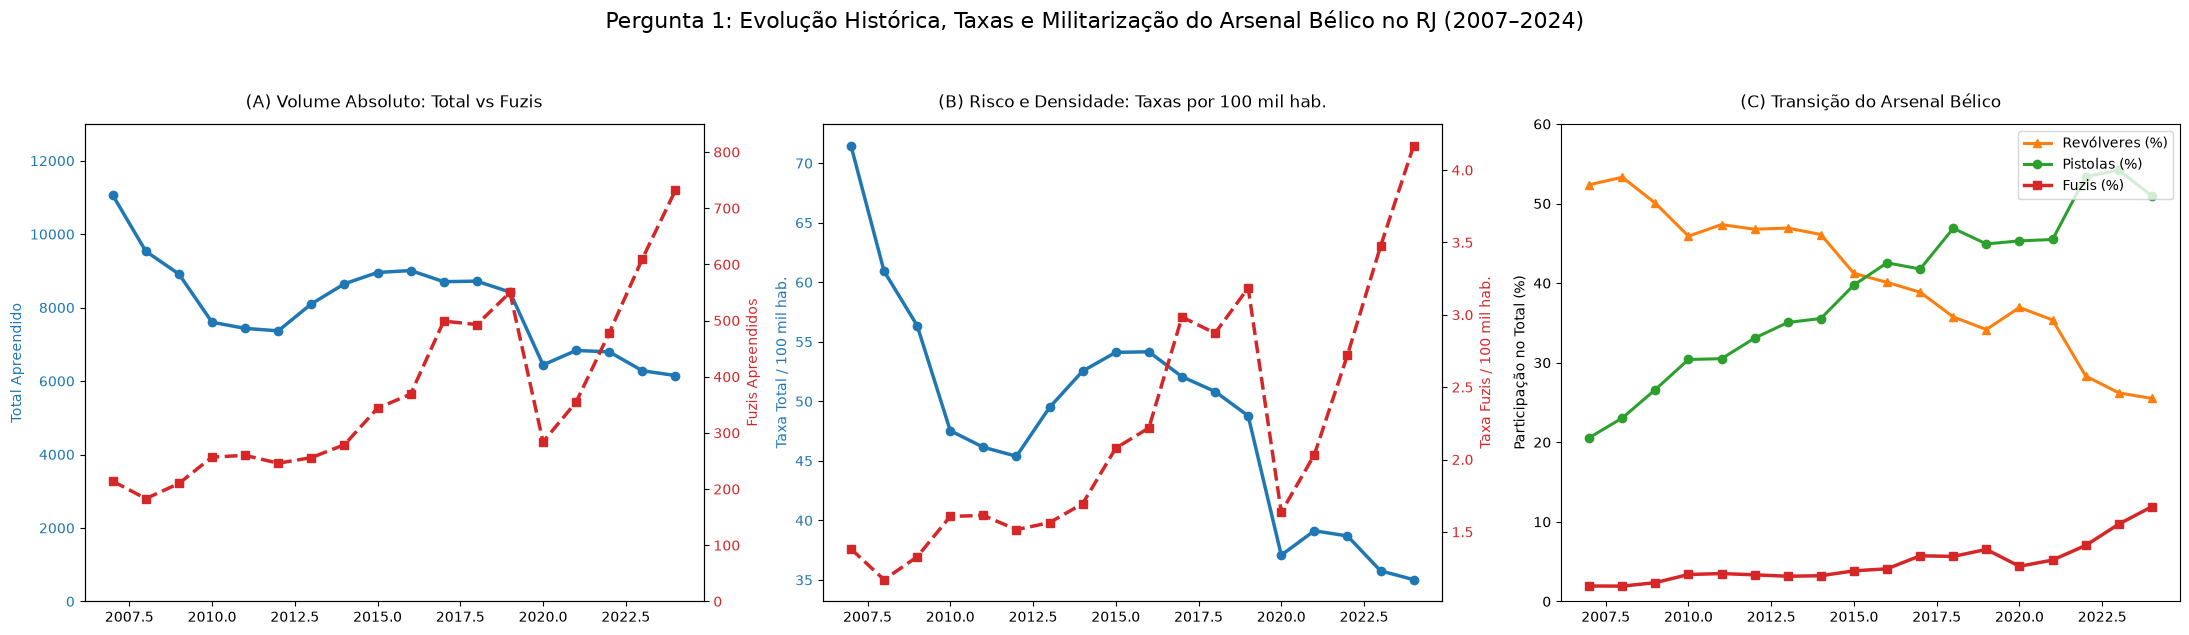

In [265]:
#######################################################################
#Limpeza dos dados
df_cisp_mensal['regiao'] = df_cisp_mensal['regiao'].replace({
    'Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i': 'Grande Niterói',
    'Grande Niteroi': 'Grande Niterói'
})
df_letalidade['regiao'] = df_letalidade['regiao'].replace({'Grande Niteroi': 'Grande Niterói'})
pop_uf = df_letalidade[df_letalidade['regiao'] == 'Estado'][['ano', 'populacao']].drop_duplicates().set_index('ano')['populacao']
########################################################################
armas_anual = df_armas[df_armas['ano'].between(2007, 2024)].groupby('ano')[['quantidade_arma_fogo_total', 'quantidade_fuzil', 'quantidade_pistola', 'quantidade_revolver']].sum()
armas_anual['populacao'] = pop_uf
armas_anual['populacao'] = armas_anual['populacao'].ffill()

armas_anual['taxa_armas_100k'] = (armas_anual['quantidade_arma_fogo_total'] / armas_anual['populacao']) * 100000
armas_anual['taxa_fuzil_100k'] = (armas_anual['quantidade_fuzil'] / armas_anual['populacao']) * 100000
armas_anual['prop_fuzil_pct'] = (armas_anual['quantidade_fuzil'] / armas_anual['quantidade_arma_fogo_total']) * 100
armas_anual['prop_pistola_pct'] = (armas_anual['quantidade_pistola'] / armas_anual['quantidade_arma_fogo_total']) * 100
armas_anual['prop_revolver_pct'] = (armas_anual['quantidade_revolver'] / armas_anual['quantidade_arma_fogo_total']) * 100

#print("Resumo Decenal da Evolução de Armas e Fuzis (Amostra Bienal):")
#display_cols = ['quantidade_arma_fogo_total', 'taxa_armas_100k', 'quantidade_fuzil', 'taxa_fuzil_100k', 'prop_revolver_pct', 'prop_pistola_pct', 'prop_fuzil_pct']
#print(armas_anual.loc[[2007, 2011, 2015, 2019, 2024], display_cols].round(2))

# Expansão para 3 painéis (1x3)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))

color1, color2 = '#1f77b4', '#d62728'

# Painel 1 (ax1): Volumes Absolutos (Seu código original)
ax1.plot(armas_anual.index, armas_anual['quantidade_arma_fogo_total'], marker='o', color=color1, linewidth=2.5, label='Total Armas')
ax1.set_xlabel('')
ax1.set_ylabel('Total Apreendido', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0, 13000)

ax1_twin = ax1.twinx()
ax1_twin.plot(armas_anual.index, armas_anual['quantidade_fuzil'], marker='s', color=color2, linewidth=2.5, linestyle='--')
ax1_twin.set_ylabel('Fuzis Apreendidos', color=color2)
ax1_twin.tick_params(axis='y', labelcolor=color2)
ax1_twin.set_ylim(0, 850)
ax1.set_title('(A) Volume Absoluto: Total vs Fuzis', pad=12)

# Painel 2 (ax2): Taxa por 100 mil habitantes (Nova inserção)
ax2.plot(armas_anual.index, armas_anual['taxa_armas_100k'], marker='o', color=color1, linewidth=2.5)
ax2.set_xlabel('')
ax2.set_ylabel('Taxa Total / 100 mil hab.', color=color1)
ax2.tick_params(axis='y', labelcolor=color1)

ax2_twin = ax2.twinx()
ax2_twin.plot(armas_anual.index, armas_anual['taxa_fuzil_100k'], marker='s', color=color2, linewidth=2.5, linestyle='--')
ax2_twin.set_ylabel('Taxa Fuzis / 100 mil hab.', color=color2)
ax2_twin.tick_params(axis='y', labelcolor=color2)
ax2.set_title('(B) Risco e Densidade: Taxas por 100 mil hab.', pad=12)

# Painel 3 (ax3): Proporções (Seu ax2 original)
anos = armas_anual.index
ax3.plot(anos, armas_anual['prop_revolver_pct'], marker='^', color='#ff7f0e', linewidth=2.2, label='Revólveres (%)')
ax3.plot(anos, armas_anual['prop_pistola_pct'], marker='o', color='#2ca02c', linewidth=2.2, label='Pistolas (%)')
ax3.plot(anos, armas_anual['prop_fuzil_pct'], marker='s', color='#d62728', linewidth=2.5, label='Fuzis (%)')
ax3.set_xlabel('')
ax3.set_ylabel('Participação no Total (%)')
ax3.set_ylim(0, 60)
ax3.set_title('(C) Transição do Arsenal Bélico', pad=12)
ax3.legend(frameon=True, facecolor='white', loc='upper right')

plt.suptitle('Pergunta 1: Evolução Histórica, Taxas e Militarização do Arsenal Bélico no RJ (2007–2024)', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()


## Pergunta 2 - Quais Áreas Integradas (AISP) concentram as maiores taxas proporcionais de letalidade violenta e feminicıdio ao longo do tempo?

### Mapa da letalidade violenta por ano



In [266]:
def baixar_shapefile_github(url: str) -> gpd.GeoDataFrame:
    """Baixa o zip do GitHub, salva num arquivo temporário e lê no GeoPandas."""
    resposta = requests.get(url, timeout=60)
    resposta.raise_for_status() 
    
    with tempfile.NamedTemporaryFile(delete=False, suffix='.zip') as tmp:
        tmp.write(resposta.content)
        tmp_path = tmp.name
        
    try:
        gdf = gpd.read_file(f"zip://{tmp_path}")
    finally:
        os.unlink(tmp_path)
        
    return gdf

def carregar_e_preparar_dados(dataframes: dict) -> dict:
    """Consolida as bases tabulares em memória e lê os shapefiles diretamente do GitHub."""
    # 1. Bases tabulares
    df_armas = dataframes["armas_apreendidas_mensal"]
    df_cisp_mensal = dataframes["evolucao_mensal_cisp"]
    df_mun_mensal = dataframes["evolucao_mensal_municipio"]
    df_taxa_mun_mensal = dataframes["taxa_evolucao_mensal_municipio"]
    df_fem_cisp = dataframes["feminicidio_mensal_cisp"]
    df_letalidade = dataframes["taxa_letalidade"]
    df_policial = dataframes["evolucao_policial_morto_servico_mensal"]
    df_rel = dataframes["relacao_cisp_aisp_risp"]
    
    # 2. Bases espaciais
    base_url = "https://raw.githubusercontent.com/josue-fgv/AEDV-A2-/main/Projeto/Datas"
    print("Baixando shapefiles de forma segura...")
    gdf_cisp = baixar_shapefile_github(f"{base_url}/CISP.zip")
    gdf_risp = baixar_shapefile_github(f"{base_url}/RISP.zip")
    gdf_aisp = baixar_shapefile_github(f"{base_url}/AISP.zip")
    print("Arquivos espaciais carregados com sucesso!")
    
    # 3. Tratamentos e Cruzamentos
    correcao_regiao = {
        "Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i": "Grande Niterói",
        "Grande Niteroi": "Grande Niterói"
    }
    df_cisp_mensal["regiao"] = df_cisp_mensal["regiao"].replace(correcao_regiao)
    df_mun_mensal["regiao"] = df_mun_mensal["regiao"].replace(correcao_regiao)
    df_letalidade["regiao"] = df_letalidade["regiao"].replace(correcao_regiao)

    aisp_names = {
        2: "AISP 02 (Botafogo/Catete)", 3: "AISP 03 (Méier/Jacarezinho)", 4: "AISP 04 (São Cristóvão/Centro)",
        5: "AISP 05 (Praça da Harmonia/Centro)", 6: "AISP 06 (Tijuca/Vila Isabel)", 7: "AISP 07 (São Gonçalo)",
        8: "AISP 08 (Campos dos Goytacazes)", 9: "AISP 09 (Rocha Miranda/Madureira)", 10: "AISP 10 (Barra do Piraí/Valença)",
        11: "AISP 11 (Nova Friburgo)", 12: "AISP 12 (Niterói/Maricá)", 14: "AISP 14 (Bangu/Senador Camará)",
        15: "AISP 15 (Duque de Caxias)", 16: "AISP 16 (Olaria/Penha/Alemão)", 17: "AISP 17 (Ilha do Governador)",
        18: "AISP 18 (Jacarepaguá/CDD)", 19: "AISP 19 (Copacabana)", 20: "AISP 20 (Nova Iguaçu/Mesquita)",
        21: "AISP 21 (São João de Meriti)", 22: "AISP 22 (Maré/Bonsucesso)", 23: "AISP 23 (Leblon/Rocinha)",
        24: "AISP 24 (Queimados/Japeri/Itaguaí)", 25: "AISP 25 (Cabo Frio/Região dos Lagos)", 26: "AISP 26 (Petrópolis)",
        27: "AISP 27 (Santa Cruz/Sepetiba)", 28: "AISP 28 (Volta Redonda/Barra Mansa)", 29: "AISP 29 (Itaperuna/Noroeste)",
        30: "AISP 30 (Teresópolis)", 31: "AISP 31 (Barra da Tijuca/Recreio)", 32: "AISP 32 (Macaé/Rio das Ostras)",
        33: "AISP 33 (Angra dos Reis/Costa Verde)", 34: "AISP 34 (Magé/Guapimirim)", 35: "AISP 35 (Itaboraí/Tanguá)",
        36: "AISP 36 (Santo Antônio de Pádua)", 37: "AISP 37 (Resende/Itatiaia)", 38: "AISP 38 (Três Rios/Paraíba do Sul)",
        39: "AISP 39 (Belford Roxo)", 40: "AISP 40 (Campo Grande)", 41: "AISP 41 (Irajá/Pavuna/Acari)"
    }
    aisp_coords = {
        2: (-43.182, -22.951), 3: (-43.278, -22.902), 4: (-43.218, -22.912), 5: (-43.180, -22.908),
        6: (-43.238, -22.923), 7: (-43.053, -22.826), 8: (-41.324, -21.754), 9: (-43.344, -22.856),
        10: (-43.829, -22.469), 11: (-42.531, -22.281), 12: (-43.103, -22.883), 14: (-43.466, -22.875),
        15: (-43.311, -22.785), 16: (-43.272, -22.842), 17: (-43.208, -22.805), 18: (-43.365, -22.938),
        19: (-43.185, -22.969), 20: (-43.451, -22.759), 21: (-43.372, -22.803), 22: (-43.245, -22.858),
        23: (-43.225, -22.981), 24: (-43.559, -22.716), 25: (-42.028, -22.880), 26: (-43.178, -22.505),
        27: (-43.678, -22.918), 28: (-44.104, -22.523), 29: (-41.889, -21.205), 30: (-42.966, -22.412),
        31: (-43.395, -23.001), 32: (-41.786, -22.371), 33: (-44.318, -23.006), 34: (-43.041, -22.652),
        35: (-42.859, -22.744), 36: (-42.132, -21.539), 37: (-44.447, -22.468), 38: (-43.209, -22.116),
        39: (-43.399, -22.764), 40: (-43.559, -22.902), 41: (-43.332, -22.825)
    }

    aisp_reg_map = df_cisp_mensal[df_cisp_mensal["ano"] >= 2018].groupby("id_aisp")["regiao"].agg(
        lambda x: x.mode()[0] if len(x.mode()) > 0 else "Interior"
    ).to_dict()
    aisp_reg_map[39] = "Baixada Fluminense"
    aisp_reg_map[35] = "Grande Niterói"
    
    # 1. Painel Anual por AISP (2007-2024)
    armas_aisp_yr = df_armas[df_armas["ano"].between(2007, 2024)].groupby(["ano", "id_aisp"])[
        ["quantidade_fuzil", "quantidade_pistola", "quantidade_revolver", "quantidade_arma_fogo_total"]
    ].sum().reset_index()

    crimes_aisp_yr = df_cisp_mensal[df_cisp_mensal["ano"].between(2007, 2024)].groupby(["ano", "id_aisp"])[
        ["quantidade_letalidade_violenta", "quantidade_homicidio_doloso", "quantidade_homicidio_intervencao_policial"]
    ].sum().reset_index()

    df_aisp_anual = pd.merge(armas_aisp_yr, crimes_aisp_yr, on=["ano", "id_aisp"], how="inner")
    df_aisp_anual = df_aisp_anual[df_aisp_anual["id_aisp"].isin(aisp_names.keys())].copy()
    df_aisp_anual["nome_aisp"] = df_aisp_anual["id_aisp"].map(aisp_names)
    df_aisp_anual["regiao"] = df_aisp_anual["id_aisp"].map(aisp_reg_map)
    df_aisp_anual["lon"] = df_aisp_anual["id_aisp"].map(lambda x: aisp_coords[x][0])
    df_aisp_anual["lat"] = df_aisp_anual["id_aisp"].map(lambda x: aisp_coords[x][1])
    df_aisp_anual["prop_intervencao_pct"] = np.where(
        df_aisp_anual["quantidade_letalidade_violenta"] > 0,
        (df_aisp_anual["quantidade_homicidio_intervencao_policial"] / df_aisp_anual["quantidade_letalidade_violenta"]) * 100,
        0.0
    ).round(1)

    # 2. Evolução Histórica do Arsenal Bélico (2007-2024)
    armas_uf = df_armas[df_armas["ano"].between(2007, 2024)].groupby("ano")[
        ["quantidade_arma_fogo_total", "quantidade_fuzil", "quantidade_pistola", "quantidade_revolver"]
    ].sum().reset_index()
    armas_uf["Revólveres (%)"] = ((armas_uf["quantidade_revolver"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Pistolas (%)"] = ((armas_uf["quantidade_pistola"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Fuzis (%)"] = ((armas_uf["quantidade_fuzil"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Outras Armas (%)"] = (100 - (armas_uf["Revólveres (%)"] + armas_uf["Pistolas (%)"] + armas_uf["Fuzis (%)"])).round(2)
    
    # 3. Cruzamento Municipal Letalidade Violenta vs. Feminicídio (2016-2024)
    taxa_mun_media = (
        df_taxa_mun_mensal[df_taxa_mun_mensal["ano"].between(2016, 2024)]
        .groupby(["ano", "id_municipio"])["taxa_letalidade_violenta"].sum()
        .reset_index()
        .groupby("id_municipio")["taxa_letalidade_violenta"].mean()
        .reset_index()
    )
    m_pop = pd.merge(
        df_taxa_mun_mensal[["ano", "mes", "id_municipio", "taxa_registro_ocorrencia"]],
        df_mun_mensal[["ano", "mes", "id_municipio", "quantidade_registro_ocorrencia", "regiao"]],
        on=["ano", "mes", "id_municipio"]
    )
    m_pop["pop"] = (m_pop["quantidade_registro_ocorrencia"] / m_pop["taxa_registro_ocorrencia"]) * 100000
    pop_mun = m_pop[m_pop["ano"].between(2016, 2024)].groupby("id_municipio").agg(
        populacao=("pop", "mean"),
        regiao=("regiao", lambda x: x.mode()[0] if len(x.mode()) > 0 else "Interior")
    ).reset_index()

    fem_mun = df_fem_cisp[df_fem_cisp["ano"].between(2016, 2024)].groupby("id_municipio")[
        ["quantidade_morte_feminicidio", "quantidade_tentativa_feminicidio"]
    ].sum().reset_index()
    fem_mun["morte_fem_anual"] = fem_mun["quantidade_morte_feminicidio"] / 9.0

    df_mun_comp = pd.merge(taxa_mun_media, pop_mun, on="id_municipio")
    df_mun_comp = pd.merge(df_mun_comp, fem_mun, on="id_municipio")
    df_mun_comp["taxa_feminicidio_100k"] = ((df_mun_comp["morte_fem_anual"] / df_mun_comp["populacao"]) * 100000).round(2)
    df_mun_comp["taxa_letalidade_violenta"] = df_mun_comp["taxa_letalidade_violenta"].round(2)
    df_mun_comp["populacao"] = df_mun_comp["populacao"].round(0).astype(int)

    mun_nomes = {
        3304557: "Rio de Janeiro", 3301702: "Duque de Caxias", 3304904: "São Gonçalo", 3303500: "Nova Iguaçu",
        3300456: "Belford Roxo", 3305109: "São João de Meriti", 3303302: "Niterói", 3301009: "Campos dos Goytacazes",
        3300704: "Cabo Frio", 3302403: "Macaé", 3302007: "Itaguaí", 3302270: "Japeri", 3304144: "Queimados",
        3302700: "Maricá", 3302502: "Magé", 3300100: "Angra dos Reis", 3305505: "Saquarema", 3300209: "Araruama",
        3306305: "Volta Redonda", 3303906: "Petrópolis", 3303401: "Nova Friburgo", 3302858: "Mesquita",
        3303203: "Nilópolis", 3304524: "Rio das Ostras", 3305554: "Seropédica", 3305208: "São Pedro da Aldeia",
        3301900: "Itaboraí", 3306008: "Três Rios", 3304201: "Resende", 3300407: "Barra Mansa",
        3304755: "S. Francisco de Itabapoana", 3300803: "Cachoeiras de Macacu", 3302205: "Itaperuna",
        3305802: "Teresópolis", 3306107: "Valença", 3300308: "Barra do Piraí", 3301876: "Guapimirim"
    }
    df_mun_grandes = df_mun_comp[df_mun_comp["populacao"] > 50000].copy()
    df_mun_grandes["nome_municipio"] = df_mun_grandes["id_municipio"].map(mun_nomes).fillna(df_mun_grandes["id_municipio"].astype(str))

    # 4. Matriz de Sazonalidade Mensal
    sazonal = df_cisp_mensal[df_cisp_mensal["ano"].between(2003, 2024)].groupby(["regiao", "mes"])["quantidade_letalidade_violenta"].sum().unstack()
    sazonal_index = (sazonal.div(sazonal.mean(axis=1), axis=0) * 100).round(2)
    sazonal_index.columns = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

    df_let_reg = df_letalidade[df_letalidade["delito"] == "Letalidade Violenta"].sort_values("ano").copy()

    return {
        "aisp_anual": df_aisp_anual,
        "armas_uf": armas_uf,
        "municipios": df_mun_grandes,
        "sazonal_index": sazonal_index,
        "regional_series": df_let_reg,
        'armas': df_armas,
        'cisp_mensal': df_cisp_mensal,
        'mun_mensal': df_mun_mensal,
        'taxa_mun_mensal': df_taxa_mun_mensal,
        'fem_cisp': df_fem_cisp,
        'letalidade': df_letalidade,
        'policial': df_policial,
        'relacao': df_rel,
        'geo_cisp': gdf_cisp,
        'geo_risp': gdf_risp,
        'geo_aisp': gdf_aisp
    }

In [267]:
def criar_fig2_mapa_poligonos_animado(df_aisp_anual: pd.DataFrame, gdf_aisp: gpd.GeoDataFrame):
    # 1. Padronizar a chave de cruzamento
    if 'aisp' in gdf_aisp.columns:
        gdf_aisp = gdf_aisp.rename(columns={'aisp': 'id_aisp'})
    elif 'AISP' in gdf_aisp.columns:
        gdf_aisp = gdf_aisp.rename(columns={'AISP': 'id_aisp'})

    # Forçar WGS 84 (Latitude/Longitude) e simplificar a malha
    if gdf_aisp.crs is None or gdf_aisp.crs.to_epsg() != 4326:
        gdf_aisp = gdf_aisp.to_crs(epsg=4326)
    
    gdf_aisp.geometry = gdf_aisp.geometry.simplify(tolerance=0.01)
    
    # Definir o ID como índice para a ligação com o Plotly
    gdf_aisp = gdf_aisp.set_index("id_aisp")

    # 2. Isolar os dados tabulares (dinâmicos) sem multiplicar a geometria
    df_anim = df_aisp_anual[df_aisp_anual["ano"].between(2018, 2024)].copy()
    df_anim = df_anim.sort_values(["ano", "id_aisp"])

    # 3. Geração do Mapa Coroplético Animado (Agora associado à métrica criminal)
    fig = px.choropleth_map(
        df_anim,
        geojson=gdf_aisp.geometry,
        locations="id_aisp",
        color="quantidade_letalidade_violenta",  # A cor passa a refletir o volume do crime
        color_continuous_scale="Reds",           # Escala térmica
        range_color=[0, df_anim["quantidade_letalidade_violenta"].max()], # Fixa a legenda para a animação
        animation_frame="ano",           
        hover_name="nome_aisp",
        hover_data={
            "id_aisp": False,
            "regiao": True,                      # Mantém a região visível no hover
            "quantidade_letalidade_violenta": True,
            "quantidade_fuzil": True
        },
        center={"lat": -22.55, "lon": -43.15},
        zoom=7.4,
        map_style="carto-positron",
        title="<b>Evolução Espaço-Temporal da Letalidade Violenta (Polígonos das AISPs)</b>"
    )

    fig.update_traces(marker_opacity=0.75, marker_line_width=0.5)
    fig.update_layout(height=650, margin=dict(l=20, r=20, t=80, b=20))
    
    return fig

In [268]:
if __name__ == "__main__":
    print("Carregando e processando bases do ISP-RJ...")
    dados = carregar_e_preparar_dados(dataframes)

    print("Gerando visualizações...")
    
    fig2 = criar_fig2_mapa_poligonos_animado(dados["aisp_anual"], dados["geo_aisp"])
    fig2.show()

Carregando e processando bases do ISP-RJ...
Baixando shapefiles de forma segura...
Arquivos espaciais carregados com sucesso!
Gerando visualizações...


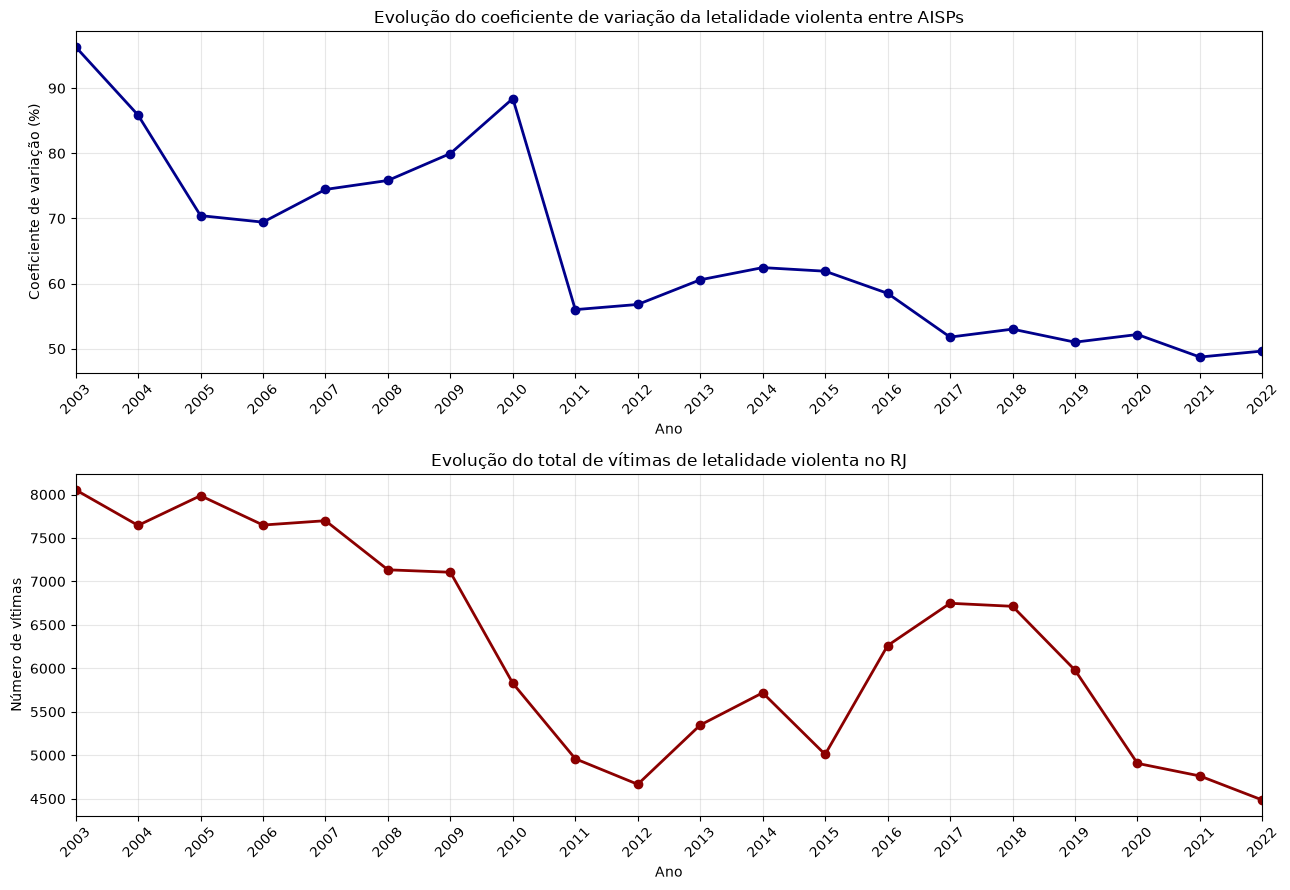

In [269]:
# 1. Coeficiente de variação por ano
cv_anual = resumo_estatistico[
    resumo_estatistico["ano"].between(2003, 2022)
].sort_values("ano")


# 2. Total de letalidades violentas por ano
letalidade_anual = (
    mortes_aisp_ano[
        mortes_aisp_ano["ano"].between(2003, 2022)
    ]
    .groupby("ano", as_index=False)["quantidade_letalidade_violenta"]
    .sum()
    .sort_values("ano")
)


# 3. Criar os gráficos
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

anos = range(2003, 2023)


# Gráfico 1 — Coeficiente de variação
axes[0].plot(
    cv_anual["ano"],
    cv_anual["coef_variacao"],
    marker="o",
    color="darkblue",
    linewidth=2
)

axes[0].set_title(
    "Evolução do coeficiente de variação da letalidade violenta entre AISPs"
)
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Coeficiente de variação (%)")
axes[0].set_xticks(anos)
axes[0].grid(alpha=0.3)


# Gráfico 2 — Total de letalidades violentas
axes[1].plot(
    letalidade_anual["ano"],
    letalidade_anual["quantidade_letalidade_violenta"],
    marker="o",
    color="darkred",
    linewidth=2
)

axes[1].set_title(
    "Evolução do total de vítimas de letalidade violenta no RJ"
)
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Número de vítimas")
axes[1].set_xticks(anos)
axes[1].grid(alpha=0.3)


# Ajustes de apresentação
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlim(2003, 2022)

plt.tight_layout()
plt.show()

Correlação entre o coeficiente de variação e o total de letalidades violentas

In [270]:

# Associar o coeficiente de variação ao total de mortes
correlacao_cv_letalidade = (
    resumo_estatistico[["ano", "coef_variacao"]]
    .merge(letalidade_anual, on="ano")
    .query("2003 <= ano <= 2022")
    .sort_values("ano")
)

correlacao_cv_letalidade

,ano,coef_variacao,quantidade_letalidade_violenta
0,2003,96.351781,8054
1,2004,85.869019,7645
2,2005,70.439578,7987
3,2006,69.437544,7649
4,2007,74.459389,7699
5,2008,75.837798,7134
6,2009,79.976854,7106
7,2010,88.415350,5828
8,2011,56.008576,4960
9,2012,56.802723,4666


Correlação de Pearson: 0.6691


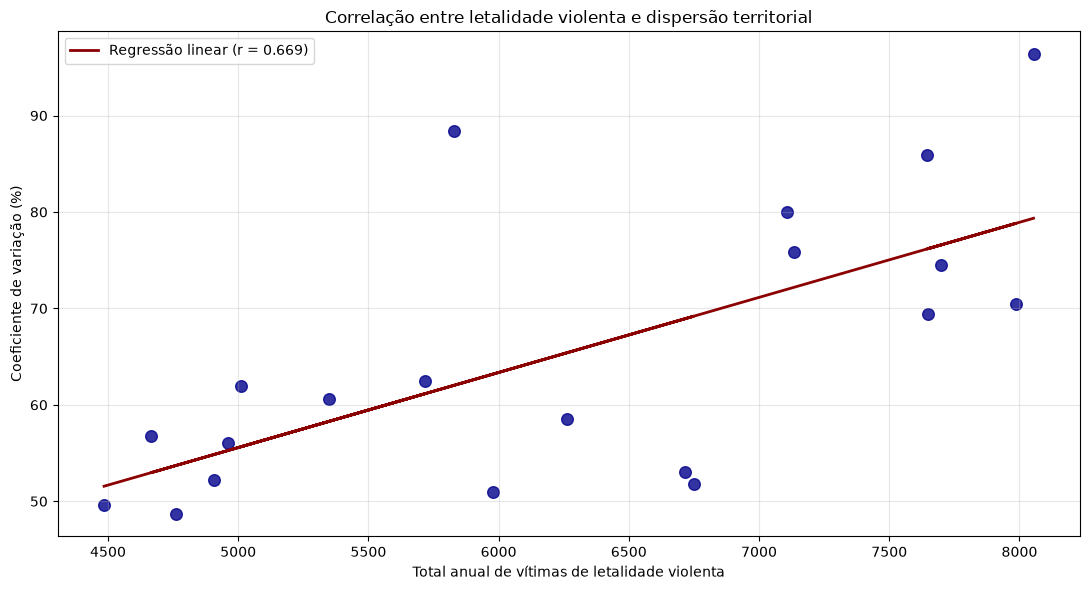

In [271]:
# Calcular correlação de Pearson
r = correlacao_cv_letalidade["coef_variacao"].corr(
    correlacao_cv_letalidade["quantidade_letalidade_violenta"]
)

print(f"Correlação de Pearson: {r:.4f}")

x = correlacao_cv_letalidade["quantidade_letalidade_violenta"]
y = correlacao_cv_letalidade["coef_variacao"]

# Ajuste da reta de regressão
a, b = np.polyfit(x, y, 1)

reta = a * x + b

plt.figure(figsize=(11, 6))

# Pontos
plt.scatter(
    x,
    y,
    color="darkblue",
    s=70,
    alpha=0.8
)

# Reta de regressão
plt.plot(
    x,
    reta,
    color="darkred",
    linewidth=2,
    label=f"Regressão linear (r = {r:.3f})"
)

plt.title(
    "Correlação entre letalidade violenta e dispersão territorial"
)

plt.xlabel("Total anual de vítimas de letalidade violenta")
plt.ylabel("Coeficiente de variação (%)")

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## Feminicídios por AISP 

In [272]:
def criar_fig_fem(df_fem_cisp: pd.DataFrame, gdf_aisp: gpd.GeoDataFrame) -> px.choropleth:

    # 1. Agrupar feminicídios por ano e AISP
    df_anual = (
        df_fem_cisp.groupby(["ano", "id_aisp"])
        .agg(
            quantidade_feminicidio = ("quantidade_morte_feminicidio", "sum")
        )
        .reset_index()
    )

    df_anual["nome_aisp"] = "AISP " + df_anual["id_aisp"].astype(str)

    # 2. Preparar dados geográficos
    gdf_aisp = gdf_aisp.copy()

    for col in ["aisp", "AISP", "id_aisp", "ID_AISP"]:
        if col in gdf_aisp.columns:
            gdf_aisp = gdf_aisp.rename(columns={col: "id_aisp"})
            break

    if gdf_aisp.crs is None:
        raise ValueError("O GeoDataFrame não possui CRS definido.")

    if gdf_aisp.crs.to_epsg() != 4326:
        gdf_aisp = gdf_aisp.to_crs(epsg=4326)

    gdf_aisp.geometry = gdf_aisp.geometry.simplify(tolerance=0.005)

    # 3. Padronizar identificadores
    gdf_aisp["id_aisp"] = gdf_aisp["id_aisp"].astype(str)
    df_anual["id_aisp"] = df_anual["id_aisp"].astype(str)

    gdf_aisp = gdf_aisp.set_index("id_aisp")

    # 4. Filtrar período
    df_anim = df_anual[df_anual["ano"].between(2018, 2024)].copy()
    df_anim = df_anim.sort_values(["ano", "id_aisp"])

    # 5. Criar mapa animado
    fig = px.choropleth_map(
        df_anim,
        geojson=gdf_aisp.geometry,
        locations="id_aisp",
        color="quantidade_feminicidio",
        color_continuous_scale="Reds",
        range_color=[0, max(df_anim["quantidade_feminicidio"].max(), 1)],
        animation_frame="ano",
        hover_name="nome_aisp",
        hover_data={
            "id_aisp": False,
            "quantidade_feminicidio": True,
        },
        center={"lat": -22.55, "lon": -43.15},
        zoom=7.4,
        map_style="carto-positron",
        title="<b>Ocorrências de Feminicídio por AISP</b>"
    )

    fig.update_traces(marker_opacity=0.75, marker_line_width=0.5)
    fig.update_layout(height=650, margin=dict(l=20, r=20, t=80, b=20))

    return fig


fig_fem = criar_fig_fem(dados["fem_cisp"], dados["geo_aisp"])
fig_fem.show()

In [273]:
df_fem_cisp 

,ano,mes,id_cisp,id_aisp,id_risp,id_municipio,quantidade_morte_feminicidio,quantidade_tentativa_feminicidio,tipo_fase,data
0,2016,12,1,5,1,3304557,0,0,Consolidado com errata,2016-12-01
1,2016,11,1,5,1,3304557,0,0,Consolidado com errata,2016-11-01
2,2016,12,10,2,1,3304557,0,0,Consolidado com errata,2016-12-01
3,2016,11,10,2,1,3304557,0,0,Consolidado com errata,2016-11-01
4,2016,11,100,37,5,3304110,0,0,Consolidado com errata,2016-11-01
...,...,...,...,...,...,...,...,...,...,...
16719,2026,4,98,10,5,3301801,0,0,Consolidado sem errata,2026-04-01
16720,2026,1,99,37,5,3302254,0,0,Consolidado sem errata,2026-01-01
16721,2026,3,99,37,5,3302254,0,0,Consolidado sem errata,2026-03-01
16722,2026,2,99,37,5,3302254,0,0,Consolidado sem errata,2026-02-01


In [274]:
# Total de feminicídios por ano
feminicidios_ano = (
    df_fem_cisp
    .groupby("ano", as_index=False)["quantidade_morte_feminicidio"]
    .sum()
)

# Total de letalidades violentas por ano
letalidades_ano = (
    mortes_aisp_ano
    .groupby("ano", as_index=False)["quantidade_letalidade_violenta"]
    .sum()
)
correlacao_feminicidio = (
    feminicidios_ano
    .merge(letalidades_ano, on="ano", validate="one_to_one")
    .query("2016 <= ano <= 2025")
    .sort_values("ano")
)

correlacao_feminicidio



,ano,quantidade_morte_feminicidio,quantidade_letalidade_violenta
0,2016,14,6262
1,2017,68,6749
2,2018,71,6714
3,2019,85,5980
4,2020,78,4907
5,2021,85,4762
6,2022,111,4485
7,2023,99,4270
8,2024,107,3809
9,2025,105,3892


Correlação de Pearson: -0.7189


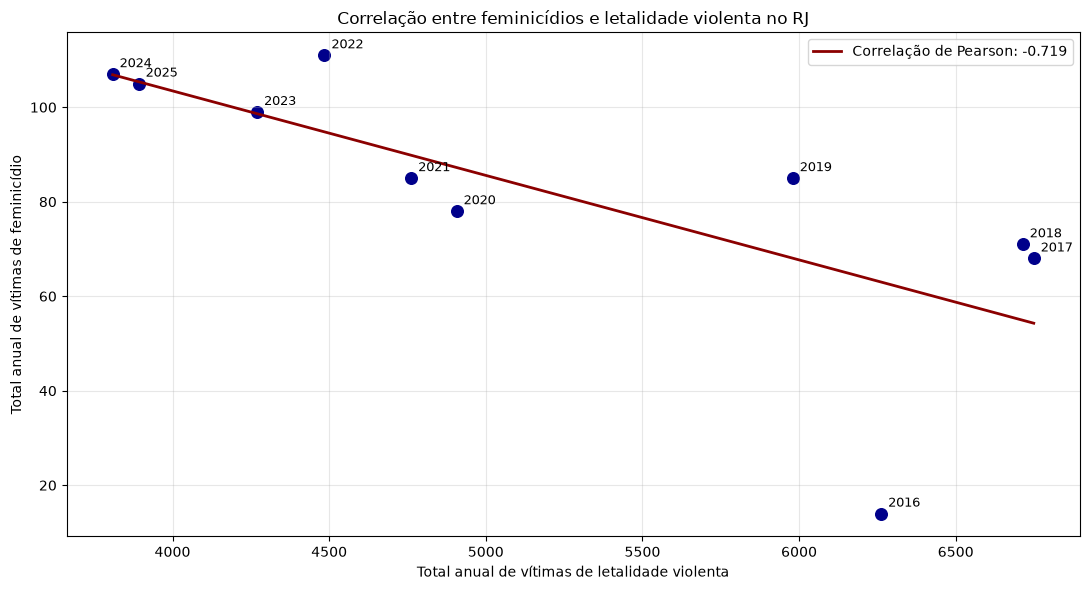

In [275]:
r = correlacao_feminicidio[
    "quantidade_morte_feminicidio"
].corr(
    correlacao_feminicidio["quantidade_letalidade_violenta"]
)

print(f"Correlação de Pearson: {r:.4f}")


import matplotlib.pyplot as plt
import numpy as np

x = correlacao_feminicidio["quantidade_letalidade_violenta"]
y = correlacao_feminicidio["quantidade_morte_feminicidio"]

# Regressão linear
a, b = np.polyfit(x, y, 1)

plt.figure(figsize=(11, 6))

# Pontos
plt.scatter(
    x,
    y,
    color="darkblue",
    s=70
)

# Reta de regressão
plt.plot(
    np.sort(x),
    a * np.sort(x) + b,
    color="darkred",
    linewidth=2,
    label=f"Correlação de Pearson: {r:.3f}"
)

# Identificar os anos
for _, linha in correlacao_feminicidio.iterrows():
    plt.annotate(
        str(int(linha["ano"])),
        (
            linha["quantidade_letalidade_violenta"],
            linha["quantidade_morte_feminicidio"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Correlação entre feminicídios e letalidade violenta no RJ")
plt.xlabel("Total anual de vítimas de letalidade violenta")
plt.ylabel("Total anual de vítimas de feminicídio")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## A variação da letalidade violenta das 3 regioes que aparecem no top 10

## Pergunta 3

In [276]:
df_regiao = df_cisp_mensal.groupby(['mes', 'id_risp'])['quantidade_letalidade_violenta'].mean().reset_index()
df_geral = df_cisp_mensal.groupby(['mes'])['quantidade_letalidade_violenta'].mean().reset_index()



nomes_regioes = {
    1: 'Capital - Zona Sul',
    2: 'Capital - Zona Oeste',
    3: 'Baixada Fluminense',
    4: 'Grande Niterói',
    5: 'Sul Fluminense',
    6: 'Norte Fluminense',
    7: 'Região Serrana'
}

df_geral_plot = df_geral.copy()
df_geral_plot['id_risp'] = 'Média Geral'
df_plotly = pd.concat([df_regiao, df_geral_plot], ignore_index=True)
df_plotly['id_risp'] = df_plotly['id_risp'].replace(nomes_regioes)

meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

fig = px.line(
    df_plotly, 
    x='mes', 
    y='quantidade_letalidade_violenta', 
    color='id_risp',
    markers=False,
    title='Média mensal de crimes por letalidade violenta',
    labels={'id_risp': ''}
)

# Alocação dos meses no eixo x
fig.update_layout(
    xaxis=dict(tickmode='array', tickvals=list(range(1, 13)), ticktext=meses),
    title_x=0.45,
    title_y=0.86,
    title_font_size=24,
    xaxis_title='',
    yaxis_title='',
    legend=dict(
        font=dict(size=14)
    )
)


fig.update_traces(
    line=dict(width=3, color='black'),
    opacity=0.6,
    selector=dict(name='Média Geral')
)

fig.show()